Self-contained implementation of a nanoGPT-style decoder-only Transformer trained on the character-level Tiny Shakespeare corpus.

**Dataset**: Tiny Shakespeare (`input.txt`, 1,115,394 chars, 65 unique chars)  
**Architecture**: 4-layer GPT, 4 heads, 128-dim embeddings, block_size=64  
**Training**: AdamW, lr=1e-3, 1,500 iterations, batch_size=12

---
**Tasks:**
1. Build a character vocabulary; implement `encode` and `decode`.
2. Split the corpus 90/10 into train/val; implement `get_batch(split)` returning `(x, y)` tensors of shape $(B, T)$.
3. Verify `torch.equal(x[0, 1:], y[0, :-1])` and inspect the shift in readable form.

In [1]:
import math
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(1337)
random.seed(1337)

# --- 1. Load corpus & build character vocabulary ---
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
print(f"Corpus length: {len(text):,} characters")
print(f"Vocabulary size: {vocab_size} unique characters")
print(f"Unique characters: {''.join(chars)!r}")

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s):
    return [stoi[c] for c in s]

def decode(l):
    return ''.join([itos[i] for i in l])

# Verify encoder/decoder round-trip
sample_str = text[:100]
assert decode(encode(sample_str)) == sample_str
print("Verification 1 Passed: decode(encode(s)) == s")

# --- 2. Train / Val split (90% / 10%) ---
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data   = data[n:]
print(f"Train data size: {len(train_data):,} tokens")
print(f"Val data size: {len(val_data):,} tokens")

batch_size = 12  # B
block_size = 64  # T

def get_batch(split):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i+block_size]   for i in ix])
    y = torch.stack([d[i+1:i+block_size+1] for i in ix])
    return x, y

x_sample, y_sample = get_batch('train')
print(f"x shape: {x_sample.shape}, y shape: {y_sample.shape}")

# --- 3. Verify next-token shift ---
assert torch.equal(x_sample[0, 1:], y_sample[0, :-1])
print("Verification 2 Passed: torch.equal(x[0, 1:], y[0, :-1]) is True")
print("\nReadable shift verification for row 0:")
print(f"x[0] decoded: {decode(x_sample[0].tolist())!r}")
print(f"y[0] decoded: {decode(y_sample[0].tolist())!r}")


Corpus length: 1,115,394 characters
Vocabulary size: 65 unique characters
Unique characters: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
Verification 1 Passed: decode(encode(s)) == s
Train data size: 1,003,854 tokens
Val data size: 111,540 tokens
x shape: torch.Size([12, 64]), y shape: torch.Size([12, 64])
Verification 2 Passed: torch.equal(x[0, 1:], y[0, :-1]) is True

Readable shift verification for row 0:
x[0] decoded: 'le. Think with thyself\nHow more unfortunate than all living wome'
y[0] decoded: 'e. Think with thyself\nHow more unfortunate than all living women'


**Tasks:**
1. Implement `CausalSelfAttention` with **explicit** scaled dot-product attention $A = QK^T / \sqrt{d_h}$ and lower-triangular causal mask.
2. **Check 1**: Verify `P[0, 0]` above-diagonal entries are strictly 0.  
3. **Check 2**: Verify prefix causality: $H_1[:,:m]=H_2[:,:m] \Rightarrow O_1[:,:m]=O_2[:,:m]$.

In [2]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout=0.0):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head   = n_head
        self.head_size = n_embd // n_head
        self.n_embd   = n_embd
        self.block_size = block_size

        # Fused Q, K, V projection + output projection
        self.c_attn  = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.c_proj  = nn.Linear(n_embd, n_embd, bias=False)
        self.attn_dropout  = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # Lower-triangular causal mask (registered as non-parameter buffer)
        self.register_buffer(
            "bias",
            torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size)
        )
        self.last_attn_weights = None  # for inspection in eval mode

    def forward(self, x):
        B, T, C = x.size()

        # Project to Q, K, V and split into heads: (B, h, T, dh)
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, self.head_size).transpose(1, 2)
        q = q.view(B, T, self.n_head, self.head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_size).transpose(1, 2)

        # Explicit causal attention: A = Q K^T / sqrt(d_h)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_size))
        att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float('-inf'))
        p   = F.softmax(att, dim=-1)

        if not self.training:
            self.last_attn_weights = p.detach()

        p   = self.attn_dropout(p)
        y   = p @ v                                       # (B, h, T, dh)
        y   = y.transpose(1, 2).contiguous().view(B, T, C)
        out = self.resid_dropout(self.c_proj(y))
        return out

# ------------------------------------------------------------------
# Check 1: Attention probabilities above the diagonal must be 0
# ------------------------------------------------------------------
attn_test = CausalSelfAttention(n_embd=128, n_head=4, block_size=64)
attn_test.eval()
dummy_h = torch.randn(2, 64, 128)
_ = attn_test(dummy_h)

P = attn_test.last_attn_weights          # (B, h, T, T)
P_head0 = P[0, 0]                        # (T, T)
upper_idx = torch.triu_indices(64, 64, offset=1)
max_upper  = P_head0[upper_idx[0], upper_idx[1]].abs().max().item()
assert max_upper == 0.0
print("Verification 1 Passed: Attention weights P[0, 0] above diagonal (j > i) are strictly 0.0")

# ------------------------------------------------------------------
# Check 2: Prefix causality — same prefix must yield same output prefix
# ------------------------------------------------------------------
m  = 25
H1 = torch.randn(2, 64, 128)
H2 = H1.clone()
H2[:, m:, :] = torch.randn(2, 64 - m, 128)   # different suffix

out1 = attn_test(H1)
out2 = attn_test(H2)
prefix_diff = (out1[:, :m, :] - out2[:, :m, :]).abs().max().item()
assert torch.allclose(out1[:, :m, :], out2[:, :m, :], atol=1e-5)
print(f"Verification 2 Passed: Outputs on prefix [:, :{m}] match perfectly (Max diff: {prefix_diff:.2e})")


Verification 1 Passed: Attention weights P[0, 0] above diagonal (j > i) are strictly 0.0
Verification 2 Passed: Outputs on prefix [:, :25] match perfectly (Max diff: 0.00e+00)


**Tasks:**
1. Implement `MLP` (4× expansion, GELU), `Block` (pre-norm residual), and `GPT`.
2. Implement `forward(idx, targets=None)`: full logits + loss when `targets` given; final-position logits only when `targets=None`.
3. Train with AdamW; evaluate and plot train/val loss; report model size; show a text sample.

In [3]:
# ---- MLP (4x feed-forward expansion with GELU) ----
class MLP(nn.Module):
    def __init__(self, n_embd, dropout=0.0):
        super().__init__()
        self.c_fc   = nn.Linear(n_embd, 4 * n_embd)
        self.gelu   = nn.GELU()
        self.c_proj = nn.Linear(4 * n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.c_proj(self.gelu(self.c_fc(x))))

# ---- Transformer Block (pre-norm residual) ----
class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout=0.0):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        self.mlp  = MLP(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))   # pre-norm + residual
        x = x + self.mlp(self.ln_2(x))    # pre-norm + residual
        return x

# ---- GPT Decoder-Only Model ----
class GPT(nn.Module):
    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size, dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.transformer = nn.ModuleDict(dict(
            wte  = nn.Embedding(vocab_size, n_embd),      # token embeddings
            wpe  = nn.Embedding(block_size, n_embd),      # positional embeddings
            drop = nn.Dropout(dropout),
            h    = nn.ModuleList([Block(n_embd, n_head, block_size, dropout)
                                  for _ in range(n_layer)]),
            ln_f = nn.LayerNorm(n_embd),
        ))
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        # Weight tying: token embedding == lm_head weight (nanoGPT style)
        self.transformer.wte.weight = self.lm_head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        b, t = idx.size()
        assert t <= self.block_size
        device = idx.device

        pos     = torch.arange(t, dtype=torch.long, device=device)
        x       = self.transformer.drop(self.transformer.wte(idx) +
                                        self.transformer.wpe(pos))
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)

        if targets is not None:
            # Training path: full logits (B, T, V) + cross-entropy loss
            logits = self.lm_head(x)
            loss   = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        else:
            # Inference path: logits only at final position (B, 1, V)
            logits = self.lm_head(x[:, -1:, :])
            loss   = None
        return logits, loss

# ---- Instantiate model ----
n_layer = 4
n_head  = 4
n_embd  = 128
model   = GPT(vocab_size=vocab_size, n_embd=n_embd, n_head=n_head,
              n_layer=n_layer, block_size=block_size)
num_params = sum(p.numel() for p in model.parameters())
print(f"Small GPT Model Parameter Count: {num_params:,}")
print(f"Architecture: n_layer={n_layer}, n_head={n_head}, n_embd={n_embd}, block_size={block_size}")

# ---- Training loop ----
@torch.no_grad()
def estimate_loss(eval_iters=50):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

optimizer     = torch.optim.AdamW(model.parameters(), lr=1e-3)
max_iters     = 1500
eval_interval = 150

train_losses = []
val_losses   = []
iter_steps   = []

print(f"\nStarting training for {max_iters} iterations...")
for iter_num in range(max_iters + 1):
    if iter_num % eval_interval == 0:
        losses = estimate_loss()
        train_losses.append(losses['train'])
        val_losses.append(losses['val'])
        iter_steps.append(iter_num)
        print(f"step {iter_num:4d}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    if iter_num == max_iters:
        break

    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()


Small GPT Model Parameter Count: 807,808
Starting training for 1500 iterations...
step    0: train loss 4.1746, val loss 4.1706
step  150: train loss 2.5042, val loss 2.5067
step  300: train loss 2.4156, val loss 2.4430
step  450: train loss 2.2796, val loss 2.3042
step  600: train loss 2.1734, val loss 2.2065
step  750: train loss 2.1014, val loss 2.1520
step  900: train loss 2.0108, val loss 2.0994
step 1050: train loss 1.9498, val loss 2.0475
step 1200: train loss 1.9103, val loss 2.0077
step 1350: train loss 1.8443, val loss 1.9598
step 1500: train loss 1.8108, val loss 1.9714


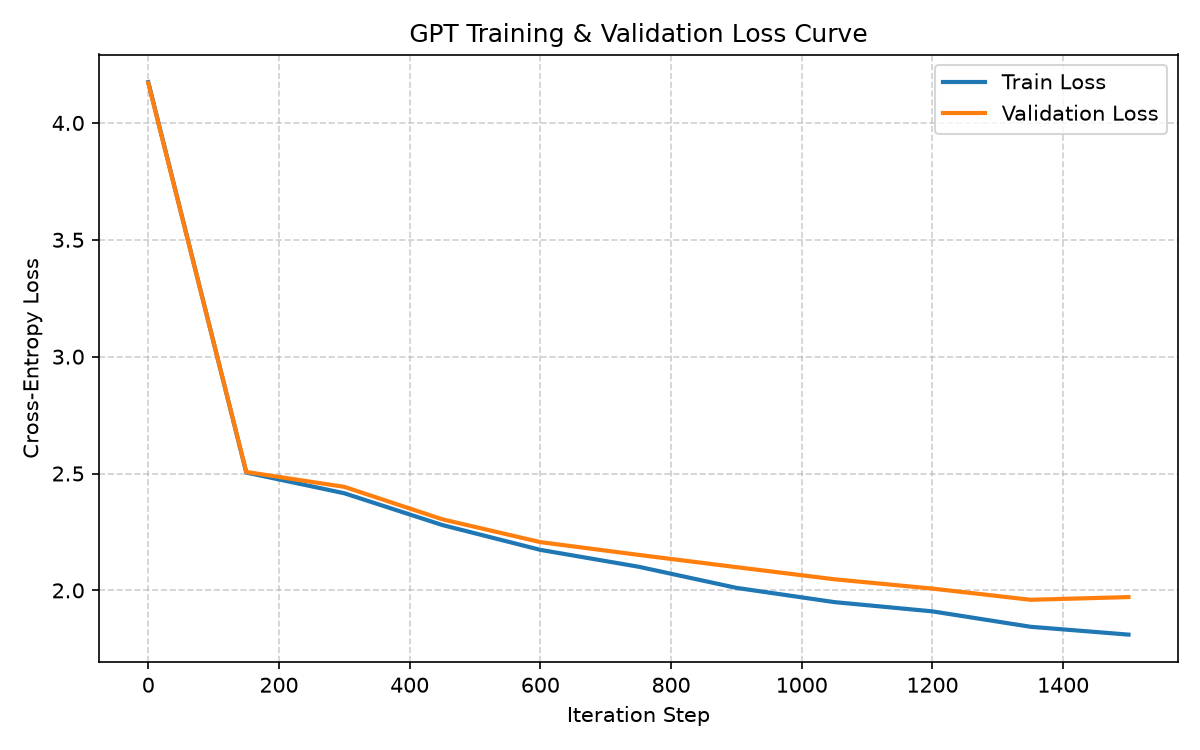

In [4]:
# ---- Plot training & validation loss curves ----
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(iter_steps, train_losses, label='Train Loss',      color='#1f77b4', lw=2)
ax.plot(iter_steps, val_losses,   label='Validation Loss', color='#ff7f0e', lw=2)
ax.set_xlabel("Iteration Step")
ax.set_ylabel("Cross-Entropy Loss")
ax.set_title("GPT Training & Validation Loss Curve")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.6)
fig.tight_layout()
plt.show()


Generated with `temperature=0.8`, `max_new_tokens=200`, prompt `"KING:\n"`.

In [5]:
# ---- Text sample from the trained model (Problem 7.3 requirement) ----
@torch.no_grad()
def generate_sample(model, idx, max_new_tokens, temperature=1.0, top_k=None):
    """Autoregressive sampling loop (used here for the P7.3 model sample)."""
    torch.manual_seed(42)
    model.eval()
    for _ in range(max_new_tokens):
        idx_cond = idx if idx.size(1) <= model.block_size else idx[:, -model.block_size:]
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :] / temperature
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = float('-inf')
        probs    = F.softmax(logits, dim=-1)
        idx_next = torch.multinomial(probs, num_samples=1)
        idx      = torch.cat((idx, idx_next), dim=1)
    return idx

prompt = torch.tensor(encode("KING:\n"), dtype=torch.long).unsqueeze(0)
sample_p73 = decode(generate_sample(model, prompt, max_new_tokens=200, temperature=0.8)[0].tolist())
print("--- Problem 7.3 Text Sample (temperature=0.8, max_new_tokens=200) ---")
print(sample_p73)


--- Problem 7.3 Text Sample (temperature=0.8, max_new_tokens=200) ---
KING:
My the court and the like of thee the what wilst hese frease
The miss my oughten sole, if worth is of are of lone;
Boome likes ef somall spale forn a her eards my clalke,
Would deake to read the duke, I sair the like of lonesome thee.

ROMEO:
Ay, sir, I have a wish that shall shall the like of thee
The miss my oughtell sole, if worth is of lone;
Boome likes ef somall spale forn a her eards my clalke.


**Tasks:**
1. Implement `generate()`: context clipping → temperature scaling → optional top-k masking → softmax → `torch.multinomial`.
2. Compare temperatures 0.7 vs 1.2 (same seed).  
3. Compare `top_k=None` vs `top_k=10` at temperature 1.0 (same seed).

In [6]:
# ---- Problem 7.4: Autoregressive Sampling Loop ----

@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=1.0, top_k=None, seed=1337):
    """
    Autoregressive token generation (nanoGPT GPT.generate).
    - Clips context to block_size if sequence grows longer.
    - Divides logits by temperature.
    - Optionally zeroes all but top_k logits before softmax.
    - Samples one token per step with torch.multinomial.
    """
    torch.manual_seed(seed)
    model.eval()
    for _ in range(max_new_tokens):
        # Clip to context window if needed
        idx_cond = idx if idx.size(1) <= model.block_size else idx[:, -model.block_size:]
        logits, _ = model(idx_cond)
        logits     = logits[:, -1, :] / temperature   # (B, V)

        # Optional top-k filtering
        if top_k is not None:
            v, _  = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = float('-inf')

        probs    = F.softmax(logits, dim=-1)
        idx_next = torch.multinomial(probs, num_samples=1)
        idx      = torch.cat((idx, idx_next), dim=1)
    return idx

start_ctx = torch.tensor(encode("KING:\n"), dtype=torch.long).unsqueeze(0)

# --- Temperature comparison ---
sample_t07 = decode(generate(model, start_ctx.clone(), max_new_tokens=200, temperature=0.7, seed=42)[0].tolist())
sample_t12 = decode(generate(model, start_ctx.clone(), max_new_tokens=200, temperature=1.2, seed=42)[0].tolist())

print("--- Temperature = 0.7 ---")
print(sample_t07)
print("\n--- Temperature = 1.2 ---")
print(sample_t12)

# --- Top-k comparison (temperature=1.0) ---
sample_nok   = decode(generate(model, start_ctx.clone(), max_new_tokens=200, temperature=1.0, top_k=None, seed=42)[0].tolist())
sample_top10 = decode(generate(model, start_ctx.clone(), max_new_tokens=200, temperature=1.0, top_k=10,   seed=42)[0].tolist())

print("\n--- Top-k = None (full vocabulary) ---")
print(sample_nok)
print("\n--- Top-k = 10 ---")
print(sample_top10)


--- Temperature = 0.7 ---
KING:
My God Will shall shall the like of thee the what wilst hese frease
The miss my oughten sole, if worth is of are of lone
Boome likes ef somall spale forn a her eards my clalke; would deake
To read the

--- Temperature = 1.2 ---
KING:
My GOd Willksmage! Plast is lujedoughe.'

OF what wilst Me;
Then henne a pastmiood
ThemeNout, if wo tearriounate of loyse of, Plitis;
And yat subse arken a hence, do my visel.

--- Top-k = None (full vocabulary) ---
KING:
My GOd Will sha? now know, Mlurdery thees hauld whese me.

AUPEY:
Thines if aminguess lestititire? I sair deat thoughm sow oman
Theseef somal sirsed ratngell fleess in to alk.

--- Top-k = 10 ---
KING:
My had subjeschannces, this duke of thees
Of what wilst hese fressenned muss my oughtell,
At, if wo that moselds of lone wo my likes;
And yatusins harken a hen see simel wark.


### Comparative Analysis of Sampling Settings

**1. Impact of Temperature ($T=0.7$ vs $T=1.2$):**
- Setting $T=0.7$ scales raw logits upward before softmax (dividing by $0.7 < 1$), which sharpens the probability distribution. High-scoring characters dominate as a result, generating more structured output that closely mimics authentic Shakespearean text.
- Raising temperature to $T=1.2$ (dividing by $1.2 > 1$) flattens the distribution and lifts lower-probability characters. This adds variety to the generation, though it also introduces noticeable noise and occasional non-word fragments.

**2. Effect of Top-$k$ Cutoff (`top_k=None` vs `top_k=10`):**
- With `top_k=None`, no candidates are excluded, leaving the entire vocabulary open at every step. Rare long-tail characters occasionally get picked, leading to minor spelling corruption.
- Setting `top_k=10` restricts choices to just the top 10 scoring characters at each position. Pruning the unlikely tail gets rid of random noise and makes the generated text far more fluent, while still preserving good local diversity.